# Tracking Tropical Weather Systems using TOBAC Algorithm

In this notebook, we will learn how to do object identification and tracking using an algorithm called `tobac`. We will apply the algorithm on a synoptic-scale tropical weather system dataset, which will be further described below.

## Importing the necessary modules

You should [create a new `conda` environment using the provided `environment.yaml`](https://docs.conda.io/projects/conda/en/latest/user-guide/tasks/manage-environments.html#creating-an-environment-from-an-environment-yml-file) to be able to import all the required modules.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import tobac
import matplotlib.animation as animation
import matplotlib.pyplot as plt
from glob import glob
from IPython.display import HTML, Image, display
from cartopy import crs as ccrs
from cartopy import util as cutil
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter

%matplotlib inline

## Loading the filtered OLR anomaly data

Outgoing longwave radiation (OLR) field is obtained from the International Satellite Cloud Climatology Project ([ISCCP](https://data.giss.nasa.gov/isccp/flux-fh/)) dataset. Anomaly is calculated by removing the seasonal and diurnal cycles. The anomaly is then decomposed into four types of tropical weather system: **Moisture Mode**, **Mixed System**, **Inertio-Gravity (IG) Wave**, and **Tropical Cyclone (TC)**. Details on the decomposition methods can be found in [Respati et al. (2026)](https://doi.org/10.5194/wcd-7-2171-2026).

In the code cell below, we are reading 4 (four) `netcdf` (`.nc`) files each containing the OLR anomaly filtered into a type of systems mentioned above. They are:
- Moisture mode: `txuptp.moisture.mode.nc`
- Mixed system: `txuptp.mixed.system.nc`
- IG wave: `txuptp.ig.wave.nc`
- TC: `txuptp.tc.nc`

Here, the filtered OLR anomaly is first standardised by dividing it by its standard deviation across time and space over the global tropics (180W&ndash;180E, 30S&ndash;30N). The variable `v_max` is the expected maximum propagation speed in `m s**-1` for each type of systems.

For this demonstration, we only provide the data for 1 month (i.e., `2001-11-01 00:00:00`&ndash;`2001-11-30 21:00:00`).

In [2]:
%%time

time_start = "2001-11-01 00:00:00"
time_end = "2001-11-30 21:00:00"

mode1 = "Moisture Mode"
mode1_file_name = "moisture.mode"
mode1_var_name = "moisture_mode"
v_max1 = 9.0

olr1 = xr.open_dataset(f"data/txuptp.{mode1_file_name}.nc")[f"txuptp_{mode1_var_name}"].sel(time=slice(time_start, time_end))
olr1_stddev = olr1.std(ddof=1)

olr1 /= olr1_stddev
olr1 = olr1.fillna(0.0)
olr1 = olr1.drop_attrs()

mode2 = "Mixed System"
mode2_file_name = "mixed.system"
mode2_var_name = "mixed_system"
v_max2 = 27.0

olr2 = xr.open_dataset(f"data/txuptp.{mode2_file_name}.nc")[f"txuptp_{mode2_var_name}"].sel(time=slice(time_start, time_end))
olr2_stddev = olr2.std(ddof=1)

olr2 /= olr2_stddev
olr2 = olr2.fillna(0.0)
olr2 = olr2.drop_attrs()

mode3 = "IG Wave"
mode3_file_name = "ig.wave"
mode3_var_name = "ig_wave"
v_max3 = 50.0

olr3 = xr.open_dataset(f"data/txuptp.{mode3_file_name}.nc")[f"txuptp_{mode3_var_name}"].sel(time=slice(time_start, time_end))
olr3_stddev = olr3.std(ddof=1)

olr3 /= olr3_stddev
olr3 = olr3.fillna(0.0)
olr3 = olr3.drop_attrs()

mode4 = "Tropical Cyclone"
mode4_file_name = "tc"
mode4_var_name = "anom_tc"
v_max4 = 10.0

olr4 = xr.open_dataset(f"data/txuptp.{mode4_file_name}.nc")[f"txuptp_{mode4_var_name}"].sel(time=slice(time_start, time_end))
olr4_stddev = olr4.std(ddof=1)

olr4 /= olr4_stddev
olr4 = olr4.fillna(0.0)
olr4 = olr4.drop_attrs()

CPU times: user 305 ms, sys: 126 ms, total: 431 ms
Wall time: 4.15 s


Now, load the total (unfiltered) OLR anomaly data (`txuptp.anom.nc`) for the same time span as above.

In [3]:
%%time

olr = xr.open_dataset("data/txuptp.anom.nc")["txuptp_anom"].sel(time=slice(time_start, time_end))

CPU times: user 8.9 ms, sys: 6.44 ms, total: 15.3 ms
Wall time: 14.5 ms


Calculate the spatial grid spacing (`dxy`) and the temporal resolution (`dt`). Currently, `tobac` only accepts rectilinear grid spacing (i.e., `dx = dy = dxy`). `dxy` has to be expressed in metre (`m`) and `dt` in second (`s`).

In [4]:
time = olr["time"]
latitude = olr["latitude"]
longitude = olr["longitude"]

dxy = np.radians(longitude.values[1] - longitude.values[0]) * 6.371e+06
dt = (time.values[1] - time.values[0]) / np.timedelta64(1, "s")

## Detecting OLR anomaly features

First, we have to set up some parameters for `feature_detection`. One of the advantages of using `tobac` is that it accepts multiple `threshold`s. Here, we use five thresholds: $-2 \sigma$, $-2.5 \sigma$, $-3 \sigma$, $-3.5 \sigma$, and $-4 \sigma$. `target` is set to `minimum` because we are seeking minima in OLR anomaly field (i.e., most negative), which are associated with strong convective activity. We also tell `tobac` that we have a periodic boundary condition (`PBC_flag`) in our longitude dimension (`hdim_2`), so that features near the longitude cyclic point are treated properly.

For more details about these parameters, please read the [documentation](https://tobac.readthedocs.io/en/latest/tobac.html#tobac.feature_detection.feature_detection_multithreshold).

In [5]:
parameters_features = {}
parameters_features["threshold"] = [-2.0, -2.5, -3.0, -3.5, -4.0]
parameters_features["target"] = "minimum"
parameters_features["position_threshold"] = "weighted_diff"
parameters_features["sigma_threshold"] = 1.0
parameters_features["n_min_threshold"] = 4
parameters_features["PBC_flag"] = "hdim_2"

Features1 = tobac.feature_detection_multithreshold(olr1, dxy, **parameters_features)
Features2 = tobac.feature_detection_multithreshold(olr2, dxy, **parameters_features)
Features3 = tobac.feature_detection_multithreshold(olr3, dxy, **parameters_features)
Features4 = tobac.feature_detection_multithreshold(olr4, dxy, **parameters_features)

Take a look at one of the results below. `tobac` defines **feature** as the detected minima (or maxima) and assigns a unique identifier (the column `feature`) to each of them. It also gives us the coordinates of the centre (`time`, `latitude`, `longitude`), the amplitude (i.e., exceeding which `threshold_value`), and the spatial extent (i.e., covering `num` number of grid points) associated with each of the detected features.

In [6]:
Features1

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,latitude,longitude
0,0,1,10.934247,124.065119,41,-2.0,1,2001-11-01 00:00:00,2001-11-01 00:00:00,-19.565753,124.565119
1,0,3,21.896586,331.658787,40,-2.0,2,2001-11-01 00:00:00,2001-11-01 00:00:00,-8.603414,332.158787
2,0,6,40.596741,231.565303,5,-2.0,3,2001-11-01 00:00:00,2001-11-01 00:00:00,10.096741,232.065303
3,0,13,22.687588,169.373773,5,-2.5,4,2001-11-01 00:00:00,2001-11-01 00:00:00,-7.812412,169.873773
4,0,14,47.645064,92.730015,32,-2.5,5,2001-11-01 00:00:00,2001-11-01 00:00:00,17.145064,93.230015
...,...,...,...,...,...,...,...,...,...,...,...
3272,239,21,60.616584,44.629485,6,-2.5,3273,2001-11-30 21:00:00,2001-11-30 21:00:00,30.116584,45.129485
3273,239,24,47.890896,351.867608,29,-3.0,3274,2001-11-30 21:00:00,2001-11-30 21:00:00,17.390896,352.367608
3274,239,25,51.883571,194.395844,31,-3.0,3275,2001-11-30 21:00:00,2001-11-30 21:00:00,21.383571,194.895844
3275,239,26,54.164081,310.672956,9,-3.0,3276,2001-11-30 21:00:00,2001-11-30 21:00:00,23.664081,311.172956


## Tracking movements of detected features through time and space

What `feature_detection` does is only detecting extrema (minima or maxima) on the field at each time step, without making any connection between subsequent time steps. This linking is done by another function (un)surprisingly called `linking`. `tobac` defines a **track** as a collection of linked **features** through time, belonging to the same (physical) system or the same **cell** (e.g., a track of a tropical cyclone).

Here, we set `stubs = 3`, which means that a track has to have at least 3 connected features, or, in other words, a cell has to "live" for at least 3 consecutive time steps. Note also that it is in this step that we now make use of the variable `v_max`.

For more details about these parameters, please read the [documentation](https://tobac.readthedocs.io/en/latest/tobac.html#tobac.tracking.linking_trackpy).

In [7]:
parameters_linking = {}
parameters_linking["stubs"] = 3
parameters_linking["method_linking"] = "predict"
parameters_linking["PBC_flag"] = "hdim_2"
parameters_linking["min_h2"] = 0
parameters_linking["max_h2"] = len(longitude.values) - 1

parameters_linking["v_max"] = v_max1
Track1 = tobac.linking_trackpy(Features1, olr1, dt=dt, dxy=dxy, **parameters_linking)

parameters_linking["v_max"] = v_max2
Track2 = tobac.linking_trackpy(Features2, olr2, dt=dt, dxy=dxy, **parameters_linking)

parameters_linking["v_max"] = v_max3
Track3 = tobac.linking_trackpy(Features3, olr3, dt=dt, dxy=dxy, **parameters_linking)

parameters_linking["v_max"] = v_max4
Track4 = tobac.linking_trackpy(Features4, olr4, dt=dt, dxy=dxy, **parameters_linking)

Frame 239: 3 trajectories present.


`linking` modifies the table (`pandas.DataFrame`) that the `feature_detection` gave us. There are two additional columns: `cell` and `time_cell`. `cell` is the unique identifier assigned to each track and `time_cell` is the age of the track at a given time.

Note that we also have `cell = -1`. This means that the corresponding feature does not belong to any track because it lives for less than three consecutive time steps (remember we set `stubs = 3`). Accordingly, these `cell = -1` features do not have any `time_cell` values (assigned `NaT`).

In [8]:
Track1

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,latitude,longitude,cell,time_cell
0,0,1,10.934247,124.065119,41,-2.0,1,2001-11-01 00:00:00,2001-11-01 00:00:00,-19.565753,124.565119,-1,NaT
1,0,3,21.896586,331.658787,40,-2.0,2,2001-11-01 00:00:00,2001-11-01 00:00:00,-8.603414,332.158787,2,0 days 00:00:00
2,0,6,40.596741,231.565303,5,-2.0,3,2001-11-01 00:00:00,2001-11-01 00:00:00,10.096741,232.065303,3,0 days 00:00:00
3,0,13,22.687588,169.373773,5,-2.5,4,2001-11-01 00:00:00,2001-11-01 00:00:00,-7.812412,169.873773,-1,NaT
4,0,14,47.645064,92.730015,32,-2.5,5,2001-11-01 00:00:00,2001-11-01 00:00:00,17.145064,93.230015,5,0 days 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3272,239,21,60.616584,44.629485,6,-2.5,3273,2001-11-30 21:00:00,2001-11-30 21:00:00,30.116584,45.129485,356,2 days 03:00:00
3273,239,24,47.890896,351.867608,29,-3.0,3274,2001-11-30 21:00:00,2001-11-30 21:00:00,17.390896,352.367608,-1,NaT
3274,239,25,51.883571,194.395844,31,-3.0,3275,2001-11-30 21:00:00,2001-11-30 21:00:00,21.383571,194.895844,370,1 days 12:00:00
3275,239,26,54.164081,310.672956,9,-3.0,3276,2001-11-30 21:00:00,2001-11-30 21:00:00,23.664081,311.172956,379,0 days 21:00:00


Let's take a look at cell #374 of the moisture mode. Below are the positions of this particular system during its lifetime.

In [9]:
Track1.loc[Track1["cell"].values == 374][["cell", "feature", "time", "latitude", "longitude", "time_cell", "threshold_value", "num"]]

,cell,feature,time,latitude,longitude,time_cell,threshold_value,num
3142,374,3143,2001-11-29 12:00:00,-11.430736,114.907831,0 days 00:00:00,-3.0,8
3157,374,3158,2001-11-29 15:00:00,-11.283848,114.867446,0 days 03:00:00,-3.0,10
3172,374,3173,2001-11-29 18:00:00,-11.210851,114.849002,0 days 06:00:00,-3.0,16
3187,374,3188,2001-11-29 21:00:00,-11.211523,115.019612,0 days 09:00:00,-3.0,17
3200,374,3201,2001-11-30 00:00:00,-11.214358,115.215422,0 days 12:00:00,-3.0,21
3211,374,3212,2001-11-30 03:00:00,-11.230986,115.533365,0 days 15:00:00,-3.0,22
3225,374,3226,2001-11-30 06:00:00,-11.472836,115.965504,0 days 18:00:00,-3.5,5
3237,374,3238,2001-11-30 09:00:00,-11.290584,116.253449,0 days 21:00:00,-3.5,9
3247,374,3248,2001-11-30 12:00:00,-11.192089,116.591946,1 days 00:00:00,-3.5,11
3256,374,3257,2001-11-30 15:00:00,-11.158052,116.891050,1 days 03:00:00,-3.5,15


Usually, we are only interested in long-lived, propagating cells for our analysis. So, we can safely discard all the `cell = -1` features from our tables. After this clean up, we need to reorder the row index of our tables for the `segmentation` function we use in the following section.

In [10]:
Track1 = Track1.loc[Track1["cell"] != -1]
Track2 = Track2.loc[Track2["cell"] != -1]
Track3 = Track3.loc[Track3["cell"] != -1]
Track4 = Track4.loc[Track4["cell"] != -1]

Track1.index = np.arange(0, len(Track1.index), 1, dtype=int)
Track2.index = np.arange(0, len(Track2.index), 1, dtype=int)
Track3.index = np.arange(0, len(Track3.index), 1, dtype=int)
Track4.index = np.arange(0, len(Track4.index), 1, dtype=int)

In [11]:
Track1

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,latitude,longitude,cell,time_cell
0,0,3,21.896586,331.658787,40,-2.0,2,2001-11-01 00:00:00,2001-11-01 00:00:00,-8.603414,332.158787,2,0 days 00:00:00
1,0,6,40.596741,231.565303,5,-2.0,3,2001-11-01 00:00:00,2001-11-01 00:00:00,10.096741,232.065303,3,0 days 00:00:00
2,0,14,47.645064,92.730015,32,-2.5,5,2001-11-01 00:00:00,2001-11-01 00:00:00,17.145064,93.230015,5,0 days 00:00:00
3,0,19,50.498118,284.423634,11,-3.0,7,2001-11-01 00:00:00,2001-11-01 00:00:00,19.998118,284.923634,7,0 days 00:00:00
4,1,3,21.903951,168.922284,31,-2.0,8,2001-11-01 03:00:00,2001-11-01 03:00:00,-8.596049,169.422284,8,0 days 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3094,239,17,41.680420,261.939506,16,-2.5,3272,2001-11-30 21:00:00,2001-11-30 21:00:00,11.180420,262.439506,382,0 days 15:00:00
3095,239,21,60.616584,44.629485,6,-2.5,3273,2001-11-30 21:00:00,2001-11-30 21:00:00,30.116584,45.129485,356,2 days 03:00:00
3096,239,25,51.883571,194.395844,31,-3.0,3275,2001-11-30 21:00:00,2001-11-30 21:00:00,21.383571,194.895844,370,1 days 12:00:00
3097,239,26,54.164081,310.672956,9,-3.0,3276,2001-11-30 21:00:00,2001-11-30 21:00:00,23.664081,311.172956,379,0 days 21:00:00


## Drawing spatial boundaries of the detected cells

The next step we are going to do is to determine some sort of masks of whether a grid point at a given time is within any of the detected cells. This is done by the `segmentation` function. Technically, this function can be called either before or after the `linking`. If you don't care about the short-lived, (probably) non-propagating `cell = -1` features, you can call the `segmentation` before the `linking` and use the `Feature` variable instead of `Track` as the input.

The output `Mask` variable is an `xarray.DataArray` which, at each grid point and each time step, has a value of `0` if it's not within any detected cell, or `feature` if it's within a feature with that unique identifier.

For more details about this function, please read the [documentation](https://tobac.readthedocs.io/en/latest/tobac.html#tobac.segmentation.watershed_segmentation.segmentation).

In [12]:
parameters_segmentation = {}
parameters_segmentation["threshold"] = -2.0
parameters_segmentation["target"] = "minimum"
parameters_segmentation["PBC_flag"] = "hdim_2"

Mask1, Track1 = tobac.segmentation_2D(Track1, olr1, dxy=dxy, **parameters_segmentation)
Mask2, Track2 = tobac.segmentation_2D(Track2, olr2, dxy=dxy, **parameters_segmentation)
Mask3, Track3 = tobac.segmentation_2D(Track3, olr3, dxy=dxy, **parameters_segmentation)
Mask4, Track4 = tobac.segmentation_2D(Track4, olr4, dxy=dxy, **parameters_segmentation)

## Plotting some results

/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py

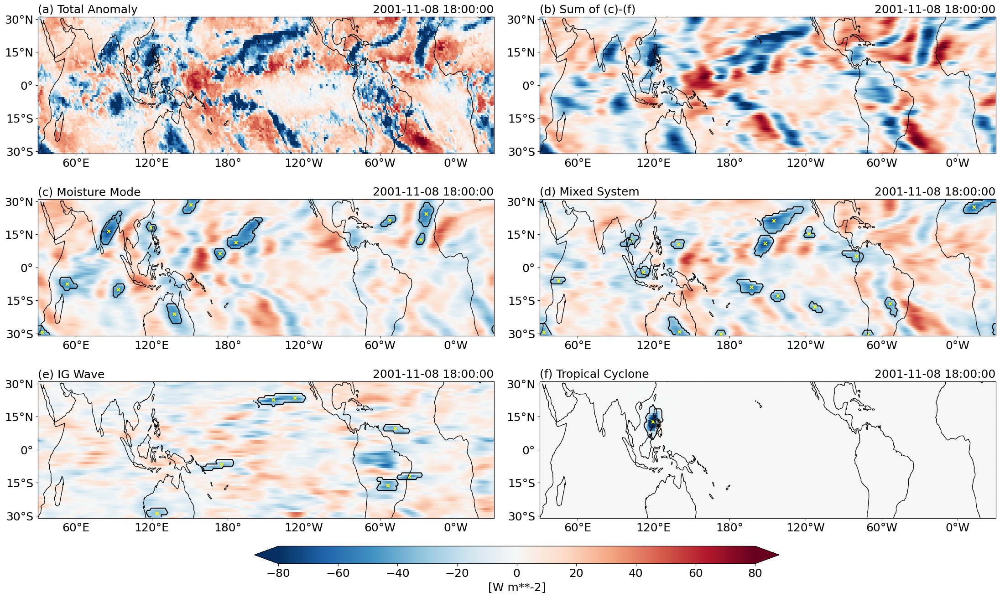

In [13]:
time_plot = "2001-11-08 18:00:00"

olr_plot = olr.sel(time=time_plot)

olr1_plot = olr1.sel(time=time_plot) * olr1_stddev
olr2_plot = olr2.sel(time=time_plot) * olr2_stddev
olr3_plot = olr3.sel(time=time_plot) * olr3_stddev
olr4_plot = olr4.sel(time=time_plot) * olr4_stddev

olr_sum_plot = olr1_plot + olr2_plot + olr3_plot + olr4_plot

Mask1_plot = Mask1.sel(time=time_plot)
Mask2_plot = Mask2.sel(time=time_plot)
Mask3_plot = Mask3.sel(time=time_plot)
Mask4_plot = Mask4.sel(time=time_plot)

Track1_plot = Track1.loc[pd.to_datetime(Track1["timestr"]) == pd.to_datetime(time_plot)]
Track2_plot = Track2.loc[pd.to_datetime(Track2["timestr"]) == pd.to_datetime(time_plot)]
Track3_plot = Track3.loc[pd.to_datetime(Track3["timestr"]) == pd.to_datetime(time_plot)]
Track4_plot = Track4.loc[pd.to_datetime(Track4["timestr"]) == pd.to_datetime(time_plot)]

Mask1_plot_c, lon1_plot_c = cutil.add_cyclic(Mask1_plot.values, Mask1_plot["longitude"].values)
Mask2_plot_c, lon2_plot_c = cutil.add_cyclic(Mask2_plot.values, Mask2_plot["longitude"].values)
Mask3_plot_c, lon3_plot_c = cutil.add_cyclic(Mask3_plot.values, Mask3_plot["longitude"].values)
Mask4_plot_c, lon4_plot_c = cutil.add_cyclic(Mask4_plot.values, Mask4_plot["longitude"].values)

lon1_plot_c = xr.DataArray(lon1_plot_c, dims=Mask1_plot["longitude"].dims, coords={"longitude": lon1_plot_c}, attrs=Mask1_plot["longitude"].attrs)
lon2_plot_c = xr.DataArray(lon2_plot_c, dims=Mask2_plot["longitude"].dims, coords={"longitude": lon2_plot_c}, attrs=Mask2_plot["longitude"].attrs)
lon3_plot_c = xr.DataArray(lon3_plot_c, dims=Mask3_plot["longitude"].dims, coords={"longitude": lon3_plot_c}, attrs=Mask3_plot["longitude"].attrs)
lon4_plot_c = xr.DataArray(lon4_plot_c, dims=Mask4_plot["longitude"].dims, coords={"longitude": lon4_plot_c}, attrs=Mask4_plot["longitude"].attrs)

Mask1_plot_c = xr.DataArray(Mask1_plot_c, dims=Mask1_plot.dims, coords={"longitude": lon1_plot_c, "latitude": Mask1_plot["latitude"]}, attrs=Mask1_plot.attrs)
Mask2_plot_c = xr.DataArray(Mask2_plot_c, dims=Mask2_plot.dims, coords={"longitude": lon2_plot_c, "latitude": Mask2_plot["latitude"]}, attrs=Mask2_plot.attrs)
Mask3_plot_c = xr.DataArray(Mask3_plot_c, dims=Mask3_plot.dims, coords={"longitude": lon3_plot_c, "latitude": Mask3_plot["latitude"]}, attrs=Mask3_plot.attrs)
Mask4_plot_c = xr.DataArray(Mask4_plot_c, dims=Mask4_plot.dims, coords={"longitude": lon4_plot_c, "latitude": Mask4_plot["latitude"]}, attrs=Mask4_plot.attrs)

fontsize = 18.0
vmin = -80.0
vmax = 80.0
markersize = 25.0
marker = "x"

figx = 23.0
figy = 14.0

fig = plt.figure(figsize=(figx, figy))

ax = fig.add_axes([1.0 / figx, 10.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
plot_olr = ax.pcolormesh(olr_plot["longitude"], olr_plot["latitude"], olr_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)

ax_sum = fig.add_axes([12.0 / figx, 10.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
plot_olr_sum = ax_sum.pcolormesh(olr_sum_plot["longitude"], olr_sum_plot["latitude"], olr_sum_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)

ax1 = fig.add_axes([1.0 / figx, 6.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
plot_olr1 = ax1.pcolormesh(olr1_plot["longitude"], olr1_plot["latitude"], olr1_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
plot_Mask1 = ax1.contour(Mask1_plot_c["longitude"], Mask1_plot_c["latitude"], Mask1_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
plot_Track1 = ax1.scatter(x=Track1_plot["longitude"], y=Track1_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())

ax2 = fig.add_axes([12.0 / figx, 6.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
plot_olr2 = ax2.pcolormesh(olr2_plot["longitude"], olr2_plot["latitude"], olr2_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
plot_Mask2 = ax2.contour(Mask2_plot_c["longitude"], Mask2_plot_c["latitude"], Mask2_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
plot_Track2 = ax2.scatter(x=Track2_plot["longitude"], y=Track2_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())

ax3 = fig.add_axes([1.0 / figx, 2.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
plot_olr3 = ax3.pcolormesh(olr3_plot["longitude"], olr3_plot["latitude"], olr3_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
plot_Mask3 = ax3.contour(Mask3_plot_c["longitude"], Mask3_plot_c["latitude"], Mask3_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
plot_Track3 = ax3.scatter(x=Track3_plot["longitude"], y=Track3_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())

ax4 = fig.add_axes([12.0 / figx, 2.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
plot_olr4 = ax4.pcolormesh(olr4_plot["longitude"], olr4_plot["latitude"], olr4_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
plot_Mask4 = ax4.contour(Mask4_plot_c["longitude"], Mask4_plot_c["latitude"], Mask4_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
plot_Track4 = ax4.scatter(x=Track4_plot["longitude"], y=Track4_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())

ax.coastlines()
ax.set_title("(a) Total Anomaly", loc="left", fontsize=fontsize)
ax.set_title(time_plot, loc="right", fontsize=fontsize)
ax.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
ax.tick_params(labelsize=fontsize)
ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
ax.yaxis.set_major_formatter(LatitudeFormatter())

ax_sum.coastlines()
ax_sum.set_title("(b) Sum of (c)-(f)", loc="left", fontsize=fontsize)
ax_sum.set_title(time_plot, loc="right", fontsize=fontsize)
ax_sum.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
ax_sum.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
ax_sum.tick_params(labelsize=fontsize)
ax_sum.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
ax_sum.yaxis.set_major_formatter(LatitudeFormatter())

ax1.coastlines()
ax1.set_title("(c) Moisture Mode", loc="left", fontsize=fontsize)
ax1.set_title(time_plot, loc="right", fontsize=fontsize)
ax1.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
ax1.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
ax1.tick_params(labelsize=fontsize)
ax1.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
ax1.yaxis.set_major_formatter(LatitudeFormatter())

ax2.coastlines()
ax2.set_title("(d) Mixed System", loc="left", fontsize=fontsize)
ax2.set_title(time_plot, loc="right", fontsize=fontsize)
ax2.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
ax2.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
ax2.tick_params(labelsize=fontsize)
ax2.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
ax2.yaxis.set_major_formatter(LatitudeFormatter())

ax3.coastlines()
ax3.set_title("(e) IG Wave", loc="left", fontsize=fontsize)
ax3.set_title(time_plot, loc="right", fontsize=fontsize)
ax3.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
ax3.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
ax3.tick_params(labelsize=fontsize)
ax3.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
ax3.yaxis.set_major_formatter(LatitudeFormatter())

ax4.coastlines()
ax4.set_title("(f) Tropical Cyclone", loc="left", fontsize=fontsize)
ax4.set_title(time_plot, loc="right", fontsize=fontsize)
ax4.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
ax4.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
ax4.tick_params(labelsize=fontsize)
ax4.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
ax4.yaxis.set_major_formatter(LatitudeFormatter())

cb_ax = fig.add_axes([0.25, 1.0 / figy, 0.5, 0.5 * figx / 30 / figy])

cb = fig.colorbar(plot_olr1, cax=cb_ax, orientation="horizontal", extend="both")

cb_ax.tick_params(labelsize=fontsize)
cb_ax.set_xlabel("[W m**-2]", fontsize=fontsize)

plt.show()

In [14]:
time_plot_start = "2001-11-06 18:00:00"
time_plot_end = "2001-11-10 18:00:00"

time_plot = time.sel(time=slice(time_plot_start, time_plot_end))

figx = 23.0
figy = 14.0

fig = plt.figure(figsize=(figx, figy))
plt.close()

def update(frame):
    olr_plot = olr.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s"))
    
    olr1_plot = olr1.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s")) * olr1_stddev
    olr2_plot = olr2.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s")) * olr2_stddev
    olr3_plot = olr3.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s")) * olr3_stddev
    olr4_plot = olr4.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s")) * olr4_stddev
    
    olr_sum_plot = olr1_plot + olr2_plot + olr3_plot + olr4_plot
    
    Mask1_plot = Mask1.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s"))
    Mask2_plot = Mask2.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s"))
    Mask3_plot = Mask3.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s"))
    Mask4_plot = Mask4.sel(time=np.datetime_as_string(time_plot[frame].values, unit="s"))
    
    Track1_plot = Track1.loc[pd.to_datetime(Track1["timestr"]) == pd.to_datetime(np.datetime_as_string(time_plot[frame].values, unit="s"))]
    Track2_plot = Track2.loc[pd.to_datetime(Track2["timestr"]) == pd.to_datetime(np.datetime_as_string(time_plot[frame].values, unit="s"))]
    Track3_plot = Track3.loc[pd.to_datetime(Track3["timestr"]) == pd.to_datetime(np.datetime_as_string(time_plot[frame].values, unit="s"))]
    Track4_plot = Track4.loc[pd.to_datetime(Track4["timestr"]) == pd.to_datetime(np.datetime_as_string(time_plot[frame].values, unit="s"))]
    
    Mask1_plot_c, lon1_plot_c = cutil.add_cyclic(Mask1_plot.values, Mask1_plot["longitude"].values)
    Mask2_plot_c, lon2_plot_c = cutil.add_cyclic(Mask2_plot.values, Mask2_plot["longitude"].values)
    Mask3_plot_c, lon3_plot_c = cutil.add_cyclic(Mask3_plot.values, Mask3_plot["longitude"].values)
    Mask4_plot_c, lon4_plot_c = cutil.add_cyclic(Mask4_plot.values, Mask4_plot["longitude"].values)
    
    lon1_plot_c = xr.DataArray(lon1_plot_c, dims=Mask1_plot["longitude"].dims, coords={"longitude": lon1_plot_c}, attrs=Mask1_plot["longitude"].attrs)
    lon2_plot_c = xr.DataArray(lon2_plot_c, dims=Mask2_plot["longitude"].dims, coords={"longitude": lon2_plot_c}, attrs=Mask2_plot["longitude"].attrs)
    lon3_plot_c = xr.DataArray(lon3_plot_c, dims=Mask3_plot["longitude"].dims, coords={"longitude": lon3_plot_c}, attrs=Mask3_plot["longitude"].attrs)
    lon4_plot_c = xr.DataArray(lon4_plot_c, dims=Mask4_plot["longitude"].dims, coords={"longitude": lon4_plot_c}, attrs=Mask4_plot["longitude"].attrs)
    
    Mask1_plot_c = xr.DataArray(Mask1_plot_c, dims=Mask1_plot.dims, coords={"longitude": lon1_plot_c, "latitude": Mask1_plot["latitude"]}, attrs=Mask1_plot.attrs)
    Mask2_plot_c = xr.DataArray(Mask2_plot_c, dims=Mask2_plot.dims, coords={"longitude": lon2_plot_c, "latitude": Mask2_plot["latitude"]}, attrs=Mask2_plot.attrs)
    Mask3_plot_c = xr.DataArray(Mask3_plot_c, dims=Mask3_plot.dims, coords={"longitude": lon3_plot_c, "latitude": Mask3_plot["latitude"]}, attrs=Mask3_plot.attrs)
    Mask4_plot_c = xr.DataArray(Mask4_plot_c, dims=Mask4_plot.dims, coords={"longitude": lon4_plot_c, "latitude": Mask4_plot["latitude"]}, attrs=Mask4_plot.attrs)
    
    fontsize = 18.0
    vmin = -80.0
    vmax = 80.0
    markersize = 25.0
    marker = "x"
    
    fig.clf()
    
    ax = fig.add_axes([1.0 / figx, 10.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
    plot_olr = ax.pcolormesh(olr_plot["longitude"], olr_plot["latitude"], olr_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    
    ax_sum = fig.add_axes([12.0 / figx, 10.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
    plot_olr_sum = ax_sum.pcolormesh(olr_sum_plot["longitude"], olr_sum_plot["latitude"], olr_sum_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    
    ax1 = fig.add_axes([1.0 / figx, 6.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
    plot_olr1 = ax1.pcolormesh(olr1_plot["longitude"], olr1_plot["latitude"], olr1_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    plot_Mask1 = ax1.contour(Mask1_plot_c["longitude"], Mask1_plot_c["latitude"], Mask1_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
    plot_Track1 = ax1.scatter(x=Track1_plot["longitude"], y=Track1_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())
    
    ax2 = fig.add_axes([12.0 / figx, 6.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
    plot_olr2 = ax2.pcolormesh(olr2_plot["longitude"], olr2_plot["latitude"], olr2_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    plot_Mask2 = ax2.contour(Mask2_plot_c["longitude"], Mask2_plot_c["latitude"], Mask2_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
    plot_Track2 = ax2.scatter(x=Track2_plot["longitude"], y=Track2_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())
    
    ax3 = fig.add_axes([1.0 / figx, 2.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
    plot_olr3 = ax3.pcolormesh(olr3_plot["longitude"], olr3_plot["latitude"], olr3_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    plot_Mask3 = ax3.contour(Mask3_plot_c["longitude"], Mask3_plot_c["latitude"], Mask3_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
    plot_Track3 = ax3.scatter(x=Track3_plot["longitude"], y=Track3_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())
    
    ax4 = fig.add_axes([12.0 / figx, 2.0 / figy, 10.0 / figx, 3.0 / figy], projection=ccrs.PlateCarree(central_longitude=210.0), aspect="auto")
    plot_olr4 = ax4.pcolormesh(olr4_plot["longitude"], olr4_plot["latitude"], olr4_plot, transform=ccrs.PlateCarree(), shading="nearest", edgecolors="face", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    plot_Mask4 = ax4.contour(Mask4_plot_c["longitude"], Mask4_plot_c["latitude"], Mask4_plot_c, transform=ccrs.PlateCarree(), levels=[0.5], colors="black")
    plot_Track4 = ax4.scatter(x=Track4_plot["longitude"], y=Track4_plot["latitude"], s=markersize, c="yellow", marker=marker, transform=ccrs.PlateCarree())
    
    ax.coastlines()
    ax.set_title("(a) Total Anomaly", loc="left", fontsize=fontsize)
    ax.set_title(np.datetime_as_string(time_plot[frame].values, unit="s"), loc="right", fontsize=fontsize)
    ax.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
    ax.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
    ax.tick_params(labelsize=fontsize)
    ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    
    ax_sum.coastlines()
    ax_sum.set_title("(b) Sum of (c)-(f)", loc="left", fontsize=fontsize)
    ax_sum.set_title(np.datetime_as_string(time_plot[frame].values, unit="s"), loc="right", fontsize=fontsize)
    ax_sum.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
    ax_sum.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
    ax_sum.tick_params(labelsize=fontsize)
    ax_sum.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax_sum.yaxis.set_major_formatter(LatitudeFormatter())
    
    ax1.coastlines()
    ax1.set_title("(c) Moisture Mode", loc="left", fontsize=fontsize)
    ax1.set_title(np.datetime_as_string(time_plot[frame].values, unit="s"), loc="right", fontsize=fontsize)
    ax1.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
    ax1.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
    ax1.tick_params(labelsize=fontsize)
    ax1.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax1.yaxis.set_major_formatter(LatitudeFormatter())
    
    ax2.coastlines()
    ax2.set_title("(d) Mixed System", loc="left", fontsize=fontsize)
    ax2.set_title(np.datetime_as_string(time_plot[frame].values, unit="s"), loc="right", fontsize=fontsize)
    ax2.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
    ax2.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
    ax2.tick_params(labelsize=fontsize)
    ax2.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax2.yaxis.set_major_formatter(LatitudeFormatter())
    
    ax3.coastlines()
    ax3.set_title("(e) IG Wave", loc="left", fontsize=fontsize)
    ax3.set_title(np.datetime_as_string(time_plot[frame].values, unit="s"), loc="right", fontsize=fontsize)
    ax3.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
    ax3.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
    ax3.tick_params(labelsize=fontsize)
    ax3.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax3.yaxis.set_major_formatter(LatitudeFormatter())
    
    ax4.coastlines()
    ax4.set_title("(f) Tropical Cyclone", loc="left", fontsize=fontsize)
    ax4.set_title(np.datetime_as_string(time_plot[frame].values, unit="s"), loc="right", fontsize=fontsize)
    ax4.set_xticks(np.arange(0.0, 360.0, 60.0), crs=ccrs.PlateCarree())
    ax4.set_yticks(np.arange(-30.0, 45.0, 15.0), crs=ccrs.PlateCarree())
    ax4.tick_params(labelsize=fontsize)
    ax4.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax4.yaxis.set_major_formatter(LatitudeFormatter())
    
    cb_ax = fig.add_axes([0.25, 1.0 / figy, 0.5, 0.5 * figx / 30 / figy])
    
    cb = fig.colorbar(plot_olr1, cax=cb_ax, orientation="horizontal", extend="both")
    
    cb_ax.tick_params(labelsize=fontsize)
    cb_ax.set_xlabel("[W m**-2]", fontsize=fontsize)

ani = animation.FuncAnimation(fig=fig, func=update, frames=len(time_plot), interval=500)

HTML(ani.to_html5_video())

/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/tobac_training/lib/python3.12/site-packages/shapely/creation.py